In [27]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

In [23]:
df = pd.read_csv("../data/CustomerInteractionData.csv")

X = df["CustomerInteractionRawText"].fillna("")
y = df["AgentAssignedTopic"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de prueba:", len(X_test))

Datos de prueba: 21


In [24]:
import joblib

modelo = joblib.load(
    "modelo_clasificacion_conversaciones.joblib"
)

print("Modelo cargado correctamente.")

Modelo cargado correctamente.


In [6]:
 def clasificar_conversacion(texto):
    prediccion = modelo.predict([texto])[0]
    return prediccion

In [7]:
texto = "Customer wants to cancel his current service"

resultado = clasificar_conversacion(texto)

print("Conversación:", texto)
print("Predicción:", resultado)

Conversación: Customer wants to cancel his current service
Predicción: Cancel Service


Confianza de predicción

In [8]:
def clasificar_conversacion_con_confianza(texto):
    # Obtener predicción
    prediccion = modelo.predict([texto])[0]

    # Obtener probabilidades
    probabilidades = modelo.predict_proba([texto])[0]

    # Obtener la probabilidad de la clase predicha
    confianza = max(probabilidades)

    return prediccion, confianza

In [9]:
texto = "Customer wants to cancel his current service"

prediccion, confianza = clasificar_conversacion_con_confianza(texto)

print("Conversación:", texto)
print("Predicción:", prediccion)
print(f"Confianza: {confianza:.2%}")

Conversación: Customer wants to cancel his current service
Predicción: Cancel Service
Confianza: 15.54%


In [10]:
#mostrar probabilidades 
def analizar_conversacion(texto):
    probabilidades = modelo.predict_proba([texto])[0]
    
    clases = modelo.classes_

    resultados = pd.DataFrame({
        "Categoría": clases,
        "Probabilidad": probabilidades
    })

    resultados = resultados.sort_values(
        "Probabilidad",
        ascending=False
    ).reset_index(drop=True)

    return resultados

In [11]:
texto = "Customer wants to cancel his current service"

analisis = analizar_conversacion(texto)

analisis

,Categoría,Probabilidad
0,Cancel Service,0.155441
1,Port Out,0.126119
2,Deactivate,0.125084
3,Others,0.111781
4,Change Plans,0.093712
5,High Bill,0.089151
6,Data Usage,0.082331
7,Poor Connectivity,0.078536
8,Roaming Plans,0.075293
9,Add New Line,0.062552


decision automatica

In [12]:
def clasificar_con_confianza(texto, umbral=0.70):
    probabilidades = modelo.predict_proba([texto])[0]
    
    indice = probabilidades.argmax()
    
    prediccion = modelo.classes_[indice]
    confianza = probabilidades[indice]

    if confianza >= umbral:
        estado = "Predicción automática"
    else:
        estado = "Revisión humana"

    return prediccion, confianza, estado

In [13]:
conversaciones_prueba = [
    "Customer wants to cancel his current service",
    "Customer wants to add another line",
    "Customer is complaining about a high bill",
    "Customer has poor network connectivity",
    "Customer wants to use data while travelling",
    "Customer wants to transfer their number to another provider"
]

for texto in conversaciones_prueba:
    prediccion, confianza, estado = clasificar_con_confianza(texto)

    print("Conversación:", texto)
    print("Predicción:", prediccion)
    print(f"Confianza: {confianza:.2%}")
    print("Estado:", estado)
    print("-" * 80)

Conversación: Customer wants to cancel his current service
Predicción: Cancel Service
Confianza: 15.54%
Estado: Revisión humana
--------------------------------------------------------------------------------
Conversación: Customer wants to add another line
Predicción: Add New Line
Confianza: 26.96%
Estado: Revisión humana
--------------------------------------------------------------------------------
Conversación: Customer is complaining about a high bill
Predicción: High Bill
Confianza: 22.53%
Estado: Revisión humana
--------------------------------------------------------------------------------
Conversación: Customer has poor network connectivity
Predicción: Poor Connectivity
Confianza: 19.00%
Estado: Revisión humana
--------------------------------------------------------------------------------
Conversación: Customer wants to use data while travelling
Predicción: Data Usage
Confianza: 17.74%
Estado: Revisión humana
----------------------------------------------------------------

In [14]:
def obtener_prediccion_detallada(texto):
    probabilidades = modelo.predict_proba([texto])[0]
    
    indice = probabilidades.argmax()
    
    prediccion = modelo.classes_[indice]
    confianza = probabilidades[indice]

    return prediccion, confianza, probabilidades

In [25]:
predicciones_test = modelo.predict(X_test)
probabilidades_test = modelo.predict_proba(X_test)

confianzas_test = probabilidades_test.max(axis=1)

resultados_test = pd.DataFrame({
    "Conversación": X_test.values,
    "Real": y_test.values,
    "Predicción": predicciones_test,
    "Confianza": confianzas_test
})

resultados_test.head(10)

,Conversación,Real,Predicción,Confianza
0,All India plans for Data usage. Don't want inc...,Roaming Plans,Data Usage,0.343212
1,Added a new line. Offered the customer new plans.,Add New Line,Add New Line,0.395685
2,Want to know about offers on recent bill as he...,High Bill,High Bill,0.218165
3,Gregory cancelled his services temporarily.,Cancel Service,Cancel Service,0.290176
4,#call?,Others,Others,0.134489
5,8289716467 called to complain about the connec...,Poor Connectivity,Poor Connectivity,0.274684
6,Customer terminated the offers permanently.,Deactivate,Change Plans,0.163059
7,935468R911 called to report abrupt disconectio...,Poor Connectivity,Others,0.155017
8,Wants to access News channels through phone.,Others,Cancel Service,0.124630
9,Kumar called to ask about his porting status. ...,Port Out,Port Out,0.172302


predicion

In [26]:
resultados_test["Correcto"] = (
    resultados_test["Real"] == resultados_test["Predicción"]
)

confianza_correctos = resultados_test[
    resultados_test["Correcto"]
]["Confianza"]

confianza_incorrectos = resultados_test[
    ~resultados_test["Correcto"]
]["Confianza"]

print("PREDICCIONES CORRECTAS")
print(f"Cantidad: {len(confianza_correctos)}")
print(f"Confianza promedio: {confianza_correctos.mean():.2%}")
print(f"Confianza mínima: {confianza_correctos.min():.2%}")
print(f"Confianza máxima: {confianza_correctos.max():.2%}")

print("\nPREDICCIONES INCORRECTAS")
print(f"Cantidad: {len(confianza_incorrectos)}")
print(f"Confianza promedio: {confianza_incorrectos.mean():.2%}")
print(f"Confianza mínima: {confianza_incorrectos.min():.2%}")
print(f"Confianza máxima: {confianza_incorrectos.max():.2%}")

PREDICCIONES CORRECTAS
Cantidad: 14
Confianza promedio: 23.93%
Confianza mínima: 13.45%
Confianza máxima: 39.57%

PREDICCIONES INCORRECTAS
Cantidad: 7
Confianza promedio: 18.86%
Confianza mínima: 12.46%
Confianza máxima: 34.32%


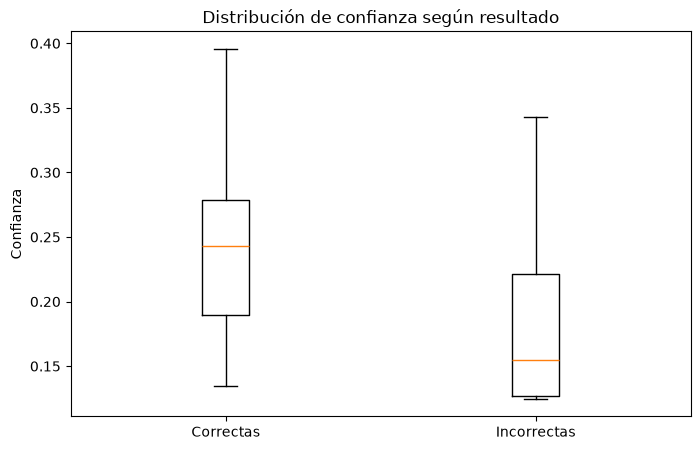

In [28]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [confianza_correctos, confianza_incorrectos],
    tick_labels=["Correctas", "Incorrectas"]
)

plt.title("Distribución de confianza según resultado")
plt.ylabel("Confianza")

plt.show()

In [30]:
UMBRAL_CONFIANZA = 0.20

def clasificar_con_confianza(texto, umbral=UMBRAL_CONFIANZA):
    
    probabilidades = modelo.predict_proba([texto])[0]
    
    indice = probabilidades.argmax()
    
    prediccion = modelo.classes_[indice]
    confianza = probabilidades[indice]

    if confianza >= umbral:
        estado = "Predicción automática"
    else:
        estado = "Revisión humana"

    return prediccion, confianza, estado

In [31]:
conversaciones_prueba = [
    "Customer wants to cancel his current service",
    "Customer wants to add another line",
    "Customer is complaining about a high bill",
    "Customer has poor network connectivity",
    "Customer wants to use data while travelling"
]

for texto in conversaciones_prueba:
    
    prediccion, confianza, estado = clasificar_con_confianza(texto)

    print("Conversación:", texto)
    print("Predicción:", prediccion)
    print(f"Confianza: {confianza:.2%}")
    print("Estado:", estado)
    print("-" * 70)

Conversación: Customer wants to cancel his current service
Predicción: Cancel Service
Confianza: 15.54%
Estado: Revisión humana
----------------------------------------------------------------------
Conversación: Customer wants to add another line
Predicción: Add New Line
Confianza: 26.96%
Estado: Predicción automática
----------------------------------------------------------------------
Conversación: Customer is complaining about a high bill
Predicción: High Bill
Confianza: 22.53%
Estado: Predicción automática
----------------------------------------------------------------------
Conversación: Customer has poor network connectivity
Predicción: Poor Connectivity
Confianza: 19.00%
Estado: Revisión humana
----------------------------------------------------------------------
Conversación: Customer wants to use data while travelling
Predicción: Data Usage
Confianza: 17.74%
Estado: Revisión humana
----------------------------------------------------------------------
